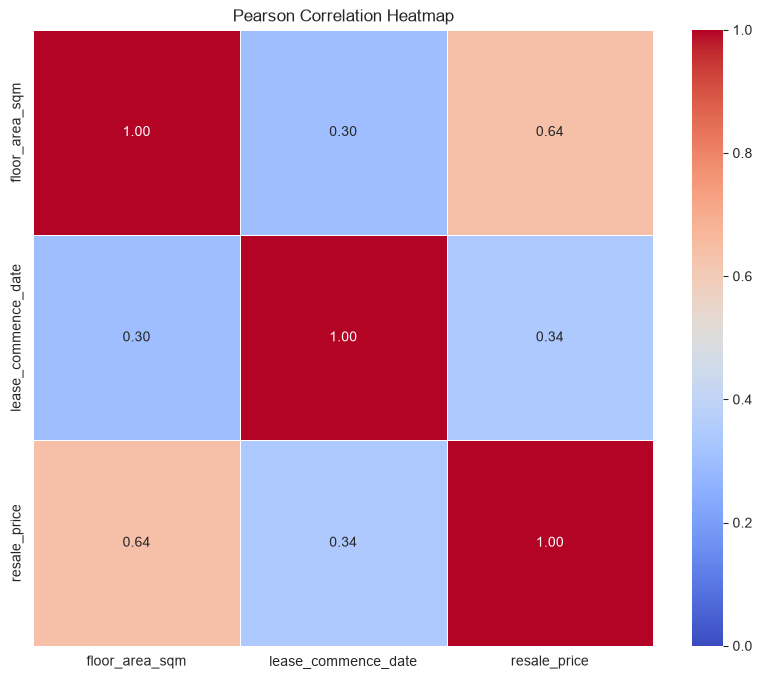

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#Load the dataset 
df = pd.read_csv('../data/resale_transactions.csv')
df.drop_duplicates(inplace=True)  # Remove duplicate rows
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')

#Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Absolute negative years values
df['lease_commence_date'] = df['lease_commence_date'].abs()

# Select continuous variables
continuous_vars_all = df[['floor_area_sqm','lease_commence_date', 'resale_price']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm',vmin=0, center=0.5, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()



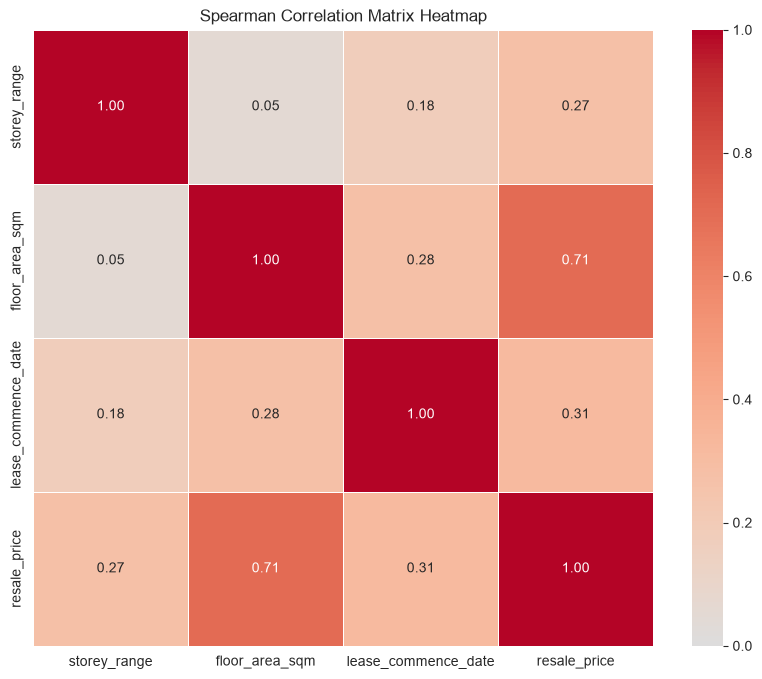

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#Load the dataset 
df = pd.read_csv('../data/resale_transactions.csv')
df.drop_duplicates(inplace=True)  # Remove duplicate rows
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')

#Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Function to convert storey_range to ordinal scale by taking the average of the range
def convert_storey_range(storey_range: str) -> float:
    """
    Converts a storey range string into its average numerical value.
    The function takes a storey range in the format 'XX TO YY', splits it into two parts,
    converts these parts to integers, and returns the average of these integers.

    Args:
    storey_range (str): A string representing a range of
    storeys, in the format 'XX TO YY'.
    Returns:
    float: The average value of the two storeys in the range.
    Example:
    convert_storey_range('07 TO 09') -> 8.0
    """
    
    range_values = storey_range.split(' TO ')
    return (int(range_values[0]) + int(range_values[1])) / 2

# Use the .apply() method to convert the 'storey_range' column with the function 
df['storey_range'] = df['storey_range'].apply(convert_storey_range)

# Select relevant columns for correlation analysis
spearman_vars = df[['storey_range', 'floor_area_sqm','lease_commence_date', 'resale_price']]

# Compute the Spearman correlation matrix
spearman_corr = spearman_vars.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()